Comparing Linear, Polynomial, and RBF Kernels on the Fashion MNIST Dataset

Step 1: Import Libraries and Load Dataset

In [2]:
from torchvision.transforms import ToTensor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from torchvision.datasets import FashionMNIST
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
# Load Fashion MNIST dataset

print("1. Downloading and loading Fashion MNIST data...")
# Load PyTorch Datasets
train_dataset = FashionMNIST(root="data", train=True, download=True, transform=ToTensor())
test_dataset = FashionMNIST(root="data", train=False, download=True, transform=ToTensor())

print("2. Converting PyTorch Tensors to NumPy arrays and flattening...")
# Extract data from the PyTorch structure
# Fashion MNIST images are 28x28. We flatten them into a 1D vector of 784 pixels.
X_train = train_dataset.data.numpy().reshape(-1, 28 * 28) / 255.0  # Normalize to [0, 1]
y_train = train_dataset.targets.numpy()

X_test = test_dataset.data.numpy().reshape(-1, 28 * 28) / 255.0   # Normalize to [0, 1]
y_test = test_dataset.targets.numpy()

1. Downloading and loading Fashion MNIST data...
2. Converting PyTorch Tensors to NumPy arrays and flattening...


Step 2: Exploratory Data Analysis

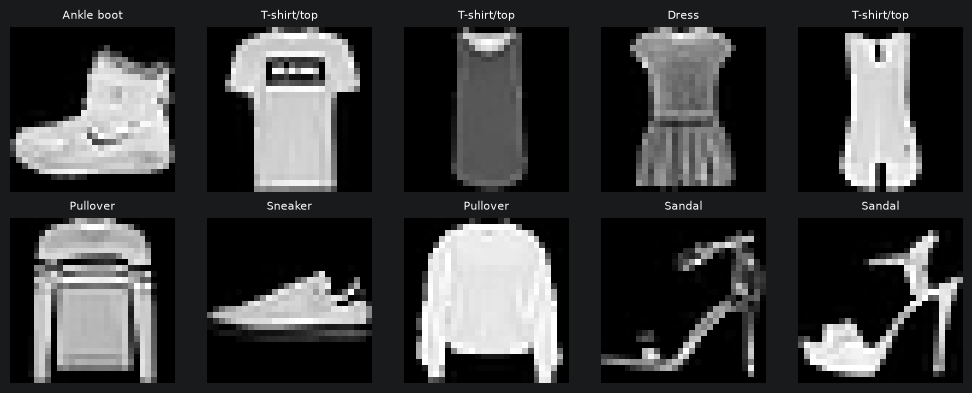

0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [3]:
# Visualize a few sample images
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat','Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(class_names[y_train[i]], fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()
# Class distribution
print(pd.Series(y_train).value_counts().sort_index())

Step 3: Preprocessing — Flatten, Subsample, Scale, and Reduce
Dimensions

In [4]:
# SVM training on the full 60,000-image dataset with non-linear kernels is very slow,
# so a stratified subsample is used to keep the lab exercise tractable.
X_sub, _, y_sub, _ = train_test_split(
X_train.reshape(len(X_train), -1), y_train,
train_size=6000, stratify=y_train, random_state=42)
# Normalize pixel values to [0, 1]
X_sub = X_sub.astype('float32') / 255.0
# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
X_sub, y_sub, test_size=0.2, random_state=42, stratify=y_sub)
# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Reduce 784 pixel features to 50 principal components to speed up SVM training
pca = PCA(n_components=50, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print(f'Explained variance retained: {pca.explained_variance_ratio_.sum():.4f}')

Explained variance retained: 0.8045


Step 4: Train SVM with Linear Kernel

In [5]:
start = time.time()
svm_linear = SVC(kernel='linear', C=1.0)
svm_linear.fit(X_train_pca, y_train)
time_linear = time.time() - start
y_pred_linear = svm_linear.predict(X_test_pca)

Step 5: Train SVM with Polynomial Kernel

In [6]:
start = time.time()
svm_poly = SVC(kernel='poly', degree=3, C=1.0, gamma='scale')
svm_poly.fit(X_train_pca, y_train)
time_poly = time.time() - start
y_pred_poly = svm_poly.predict(X_test_pca)

Step 6: Train SVM with RBF Kernel

In [7]:
start = time.time()
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_rbf.fit(X_train_pca, y_train)
time_rbf = time.time() - start
y_pred_rbf = svm_rbf.predict(X_test_pca)

Step 7: Compare Kernel Performance

Linear       Acc=0.8100 Prec=0.8104 Rec=0.8100 F1=0.8095 Time=3.03s
Polynomial   Acc=0.8000 Prec=0.8144 Rec=0.8000 F1=0.8026 Time=0.33s
RBF          Acc=0.8200 Prec=0.8199 Rec=0.8200 F1=0.8180 Time=0.24s
       Kernel  Accuracy  Precision  Recall        F1  Train Time (s)
0      Linear      0.81   0.810386    0.81  0.809549        3.031769
1  Polynomial      0.80   0.814352    0.80  0.802636        0.334409
2         RBF      0.82   0.819887    0.82  0.817958        0.238966


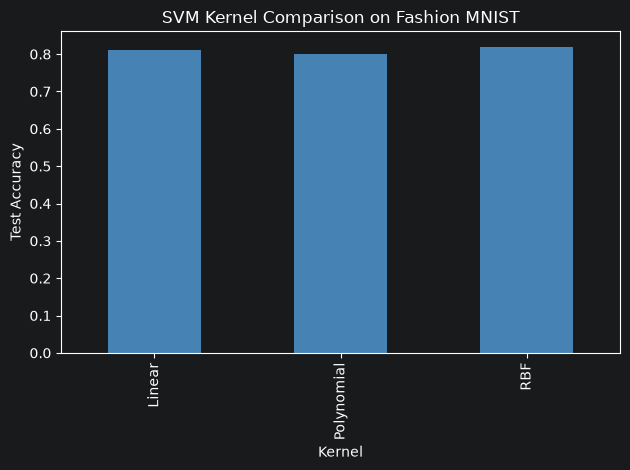

In [8]:
def evaluate(name, y_true, y_pred, train_time):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro')
    rec = recall_score(y_true, y_pred, average='macro')
    f1 = f1_score(y_true, y_pred, average='macro')
    print(f'{name:12s} Acc={acc:.4f} Prec={prec:.4f} Rec={rec:.4f} F1={f1:.4f} Time={train_time:.2f}s')
    return [name, acc, prec, rec, f1, train_time]
results = []
results.append(evaluate('Linear', y_test, y_pred_linear, time_linear))
results.append(evaluate('Polynomial', y_test, y_pred_poly, time_poly))
results.append(evaluate('RBF', y_test, y_pred_rbf, time_rbf))
results_df = pd.DataFrame(results, columns=['Kernel', 'Accuracy', 'Precision', 'Recall', 'F1', 'Train Time (s)'])
print(results_df)
results_df.plot(x='Kernel', y='Accuracy', kind='bar', legend=False, color='steelblue')
plt.ylabel('Test Accuracy')
plt.title('SVM Kernel Comparison on Fashion MNIST')
plt.tight_layout()
plt.show()

Step 8: Confusion Matrix for the Best-Performing Kernel

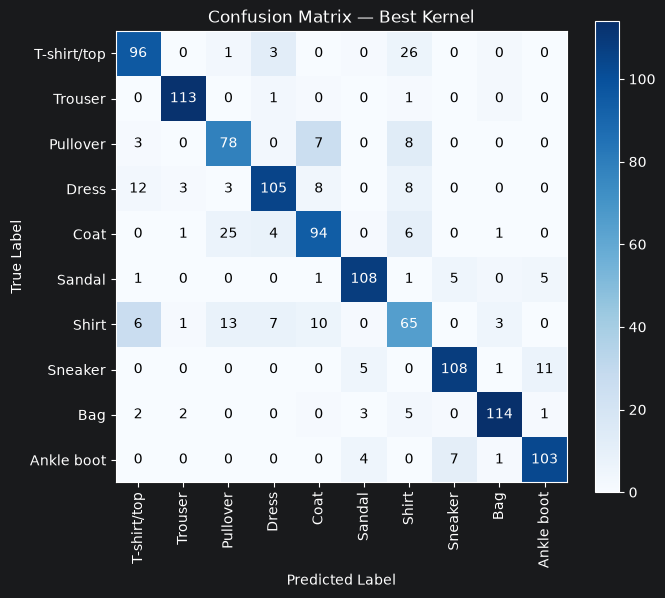

In [10]:
best_pred = y_pred_rbf # replace with whichever kernel performed best
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks(range(10), class_names, rotation=90)
plt.yticks(range(10), class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix — Best Kernel')
threshold=cm.max()/2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(i,j,str(cm[i,j]),
            horizontalalignment="center",
            verticalalignment="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

